## **A. Global Lagrange interpolation**

In [ ]:
# import all the packages here

import numpy as np
import matplotlib.pyplot as plt
import math
import scipy
from scipy import integrate
from scipy.integrate import quad
from os import error

In [ ]:
## Lagrange interpolation
#
# INPUT:
# f         scalar-valued function
# interval  interpolation interval [a,b]
# n         interpolation order
#
# OUTPUT:
# coeff     centered coefficients of Lagrange interpolant


def lagrangeInterp(f, interval, n):
  # define a linspace on the interval to use as input for np.polyfit
  a,b = interval
  nodes = np.linspace(a, b, n + 1)

  # define the midpoint of the interval
  m = (a + b)/2

  x = nodes - m   #nodes centered

  y = f(nodes)

  # compute the centered coefficients using np.polyfit
  coeff = np.polyfit( x, y, n)

  return coeff


### TEST ###

coeff = lagrangeInterp(np.sin, [0 , 2*np.pi], 1)

print("For n = 1, the coefficients should be the following:")
print(coeff)

For n = 1, the coefficients should be the following:
[-3.89817183e-17 -1.22464680e-16]


In [ ]:
## Evaluate interpolant
#   Yq = EVALUATEINTERPOLANT(C, I, Xq, N), with N=1, evaluates the Lagrange
#   interpolant defined by the coefficients C on the given interval I at the points
#   in the array Xq. C is an array of length n+1 (the indeces then being 0,...,n)
#   containing the polynomial coefficients in descending powers:
#
#      Yq[i] = C[0]*(Xq[i]-M)**n + C[1]*(Xq[i]-M)**(n-1) +...+ C[n-1]*(Xq[i]-M) + C[n],
#
#   where M is the midpoint of the interval
#      M = (I[0] + I[1]) / 2
#
#   Yq = EVALUATEINTERPOLANT(Cs, Is, Xq, N) evaluates the piecewise Lagrange
#   interpolants defined by the coefficients Cs(i, :) on the interval Is(i, :)
#   with N subintervals at the points in the array Xq.
#


def evaluateInterpolant(coeffs, intervals, xVals, N):
    fVals = np.zeros((np.size(xVals)))

    if N == 1:
        for i in range(np.size(coeffs) - 1):
            m = (intervals[0] + intervals[1]) / 2
            fVals = np.polyval(coeffs, xVals - m)
    else:
        for k in range(N):
            coeff_int = coeffs[k, :]
            I_int = intervals[k, :]
            x_int = xVals[(I_int[0] <= xVals) & (xVals <= I_int[1])]
            m = (I_int[0] + I_int[1]) / 2
            y = np.polyval(coeff_int, x_int - m)
            fVals[(I_int[0] <= xVals) & (xVals <= I_int[1])] = y

    return fVals

In [ ]:
# setting the value of p to use for all the questions in sections A and B
p = 1

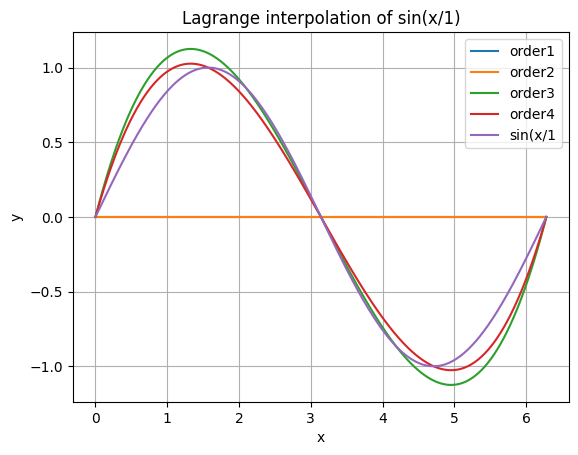

<Figure size 1200x800 with 0 Axes>

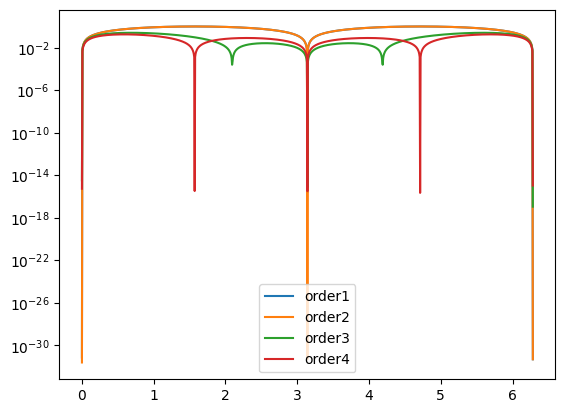

<Figure size 1200x800 with 0 Axes>

In [ ]:

# Discussion question A.1

# use "lambda functions" to define simple functions, e.g.:
f = lambda x: np.sin(x/p)
# This is equivalent to the standard function definition but more pythonic:
#       def f(x):
#           return np.sin(x)

I = [0, 2*np.pi*p]
points = int(1e3 + 1)
Xq = np.linspace(I[0], I[1], points)

for n in range(1,5):
    coeffs = lagrangeInterp(f, I, n)
    fVals = evaluateInterpolant(coeffs, I, Xq, 1)
    plt.plot(Xq, fVals ,label =  f'order{n}')

plt.plot(Xq, f(Xq), label = f'sin(x/{p}')
plt.legend()
plt.grid(True)
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Lagrange interpolation of sin(x/{p})')
plt.figure(figsize=(12, 8))
plt.show()

# adding the the original function to the plot for comparison

def MaxError(f, I, n):
    Xq = np.linspace(I[0], I[1], points)
    y = f(Xq)
    error = np.linalg.norm(y - evaluateInterpolant(lagrangeInterp(f, I, n), I, Xq, 1), np.inf)
    return error


def Error(f, I, n):
    Xq = np.linspace(I[0], I[1], points)
    y = f(Xq)
    error = abs(y - evaluateInterpolant(lagrangeInterp(f, I, n), I, Xq, 1))
    return error

for i in range(1,5):
    plt.semilogy(Xq, Error(f, I, i), label = f'order{i}') # Use semilogy for error plots
plt.legend()
plt.figure(figsize=(12, 8))
plt.show()




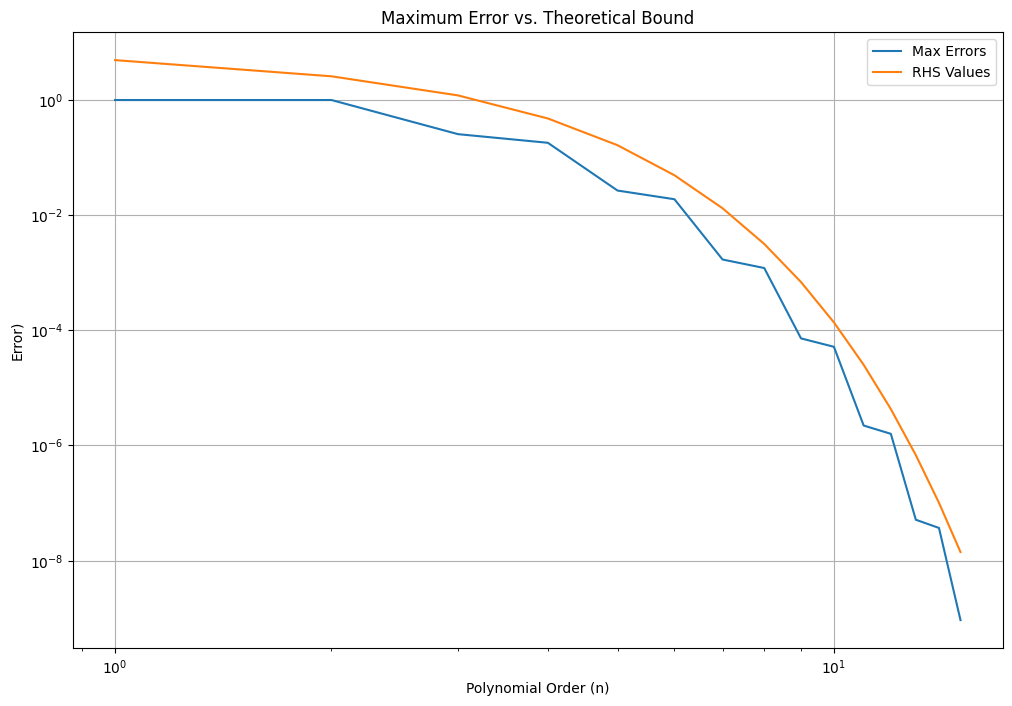

In [ ]:
ordersn = []
RHSValues = []
L = I[1] - I[0]
maxErrors = []

Domain = list(range(1, 16))
for n in range(1,16):
    newError = MaxError(f, I, n)
    maxErrors.append(newError)

    if n > 0:
      h = L / n
      max_f_nplus1_deriv = (1/p)**(n + 1)    #max derivative of f
      rhs_val = (h**(n+1)) * max_f_nplus1_deriv / (4*(n + 1))
      RHSValues.append(rhs_val)
    else:
      RHSValues.append(0)


plt.figure(figsize=(12, 8))

plt.loglog(Domain, maxErrors, label='Max Errors')
plt.loglog(Domain, RHSValues, label='RHS Values')
plt.legend()
plt.grid(True)
plt.xlabel('Polynomial Order (n)')
plt.ylabel('Error)')
plt.title('Maximum Error vs. Theoretical Bound')

plt.show()

## **B. Piecewise interpolation and stability analysis**

In [ ]:
## Piecewise interpolation
#
# INPUT:
# f             f scalar-valued function
# interval      interpolation interval [a, b]
# n             interpolation order
# N             number of subintervals
#
# OUTPUT:
# coeffs        multidimensional array, i-th element is an array containing the
#               centered coefficients of i-th subinterval (you can do it also with lists)
# intervals     multidimensional array, i-th element is an array containing the
#               beginning and endpoint of i-th subinterval (you can do it also with lists)


def piecewiseInterp(f, interval, n, N):
  a, b = interval
  H = (b - a)/N    #subinterval length
  intervals = []
  coeffs = []

  # looping over the intervals, at each step update the output variables

  for i in range(N):
     aNew = a + i*H
     bNew = a + (i + 1)*H

     intervals.append([aNew,bNew])
     nodes = np.linspace(aNew, bNew, n + 1)
     m = (aNew + bNew)/2
     x = nodes - m
     y = f(nodes)
     c = np.polyfit(x, y, n)
     coeffs.append(c)


    # defining the subinterval boundaries and then using lagrangeInterp over said subinterval


  return np.array(coeffs), np.array(intervals)

#test

coeffs, intervals = piecewiseInterp(np.sin, [0 , 2*np.pi], 1, 1)

print(f"the coefficients should be the following:")
print(coeffs)
print(f"the intervals should be the following:")
print(intervals)

the coefficients should be the following:
[[-3.89817183e-17 -1.22464680e-16]]
the intervals should be the following:
[[0.         6.28318531]]


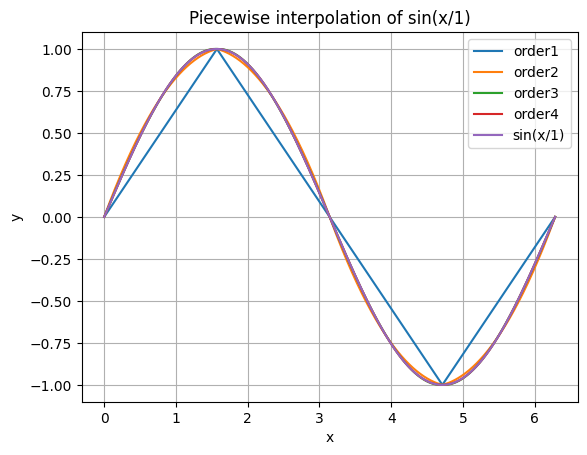

<Figure size 1200x800 with 0 Axes>

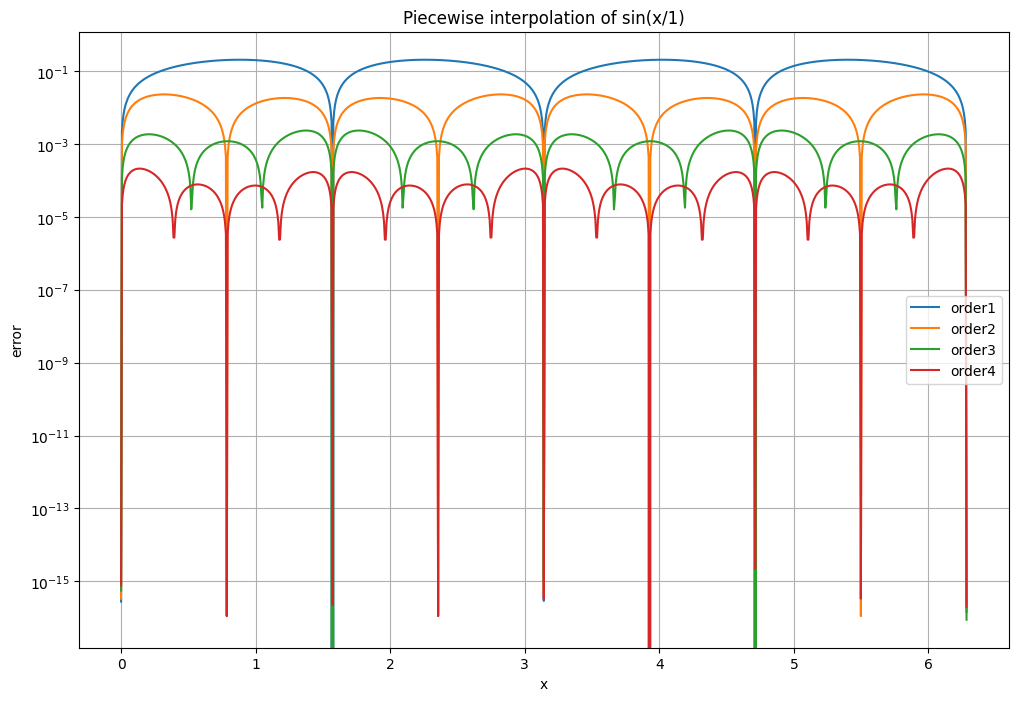

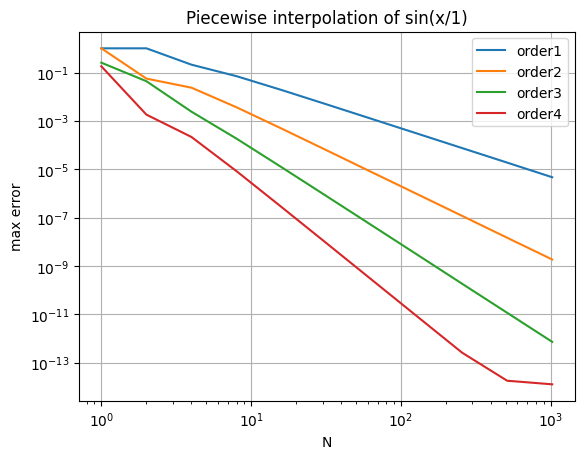

In [ ]:
## Repeat the exercise in A.1

g = lambda x: np.sin(x/p)
# This is equivalent to the standard function definition but more pythonic:
#       def f(x):
#           return np.sin(x)

I = [0, 2*np.pi*p]
points = int(1e3 + 1)
Xq = np.linspace(I[0], I[1], points)


for n in range(1,5):
    coeffsPiece, intervals = piecewiseInterp(g, I, n, 4)
    fValsPiece = evaluateInterpolant(coeffsPiece, intervals, Xq, 4)
    plt.plot(Xq, fValsPiece ,label =  f'order{n}')

plt.plot(Xq, g(Xq), label = f'sin(x/{p})')
plt.legend()
plt.grid(True)
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Piecewise interpolation of sin(x/{p})')
plt.figure(figsize=(12, 8))
plt.show()




def ErrorPiece(g, I, n, N):
    y = g(Xq)
    if N == 1:
        coeffs, intervals = lagrangeInterp(g, I, n), I
        error = abs(y - evaluateInterpolant(coeffs, intervals, Xq, N))
    else:
        coeffs2, intervals2 = piecewiseInterp(g, I, n, N)
        error = abs(y - evaluateInterpolant(coeffs2, intervals2, Xq, N))
    return error

plt.figure(figsize=(12, 8))

ErrorsB1 = []
for i in range(1,5):
    newErrorPiece = ErrorPiece(g, I, i, 4)
    ErrorsB1.append(newErrorPiece)

for j in range(4):
  plt.semilogy(Xq, ErrorsB1[j], label = f'order{j + 1}')
plt.legend()
plt.grid(True)
plt.xlabel('x')
plt.ylabel('error')
plt.title(f'Piecewise interpolation of sin(x/{p})')
plt.show()


maxErrorsB = []
nodesB = [2**l for l in range(11)]

for n in range(1, 5):
  nodeError = []
  for l in range(0, 11):
    N = 2 ** (l)
    newErrorPiece = np.max(ErrorPiece(g, I, n, N))
    nodeError.append(newErrorPiece)
  maxErrorsB.append(nodeError)

for j in range(4):
     plt.loglog(nodesB, maxErrorsB[j], label = f'order{j + 1}')

plt.legend()
plt.grid(True)
plt.xlabel('N')
plt.ylabel('max error')
plt.title(f'Piecewise interpolation of sin(x/{p})')
plt.show()





[1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
[1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
[1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
[1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]


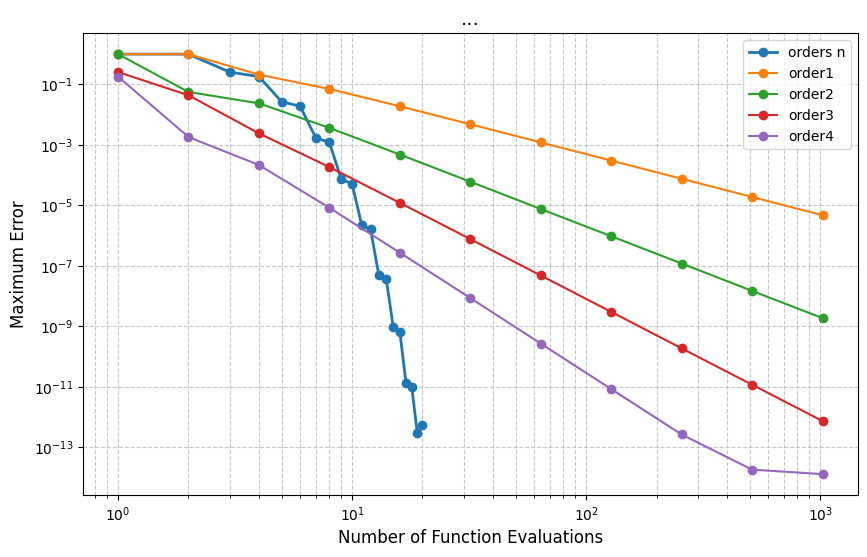

In [ ]:
# discussion question

fB2 = lambda x: np.sin(x/p)
IB2 = [0, 2 * np.pi]
points = int(1e3 + 1)
Xq = np.linspace(IB2[0], IB2[1], points)
MaxErrorB2 = []
evaluations = np.arange(1, 21)
evaluations3 = []

errorsB2 = []

for n in range(1,21):
    coeffs = lagrangeInterp(fB2, IB2, n)
    fVals = evaluateInterpolant(coeffs, IB2, Xq, 1)
    maxError = np.linalg.norm(fB2(Xq)-fVals ,np.inf)
    MaxErrorB2.append(maxError)

for n in range(1, 5):
  evaluations2 = []
  newError = []
  for l in range(0, 11):
    N = 2 ** (l)
    newErrorPiece = np.max(ErrorPiece(fB2, IB2, n, N))
    newError.append(newErrorPiece)
    evaluations2.append(N)
  errorsB2.append(newError)
  evaluations3.append(evaluations2)

for i in range(4):
  print(evaluations3[i])




plt.figure(figsize=(10, 6))
plt.loglog(evaluations, MaxErrorB2, 'o-', linewidth=2, markersize=6, label = 'orders n')

for j in range(0, 4):
  plt.loglog(evaluations3[j], errorsB2[j], 'o-' , label = f'order{j + 1}')


plt.legend()
plt.xlabel('Number of Function Evaluations', fontsize=12)
plt.ylabel('Maximum Error', fontsize=12)
plt.title('...', fontsize=14)
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.savefig('error_plot.png')
plt.show()


# Global interpolation - (n + 1) many evaluations (one for every node)
# Piecewise interpolation - N subintervals with lower order (small_n) polynomials - N times (small_n + 1)
# many evaluations



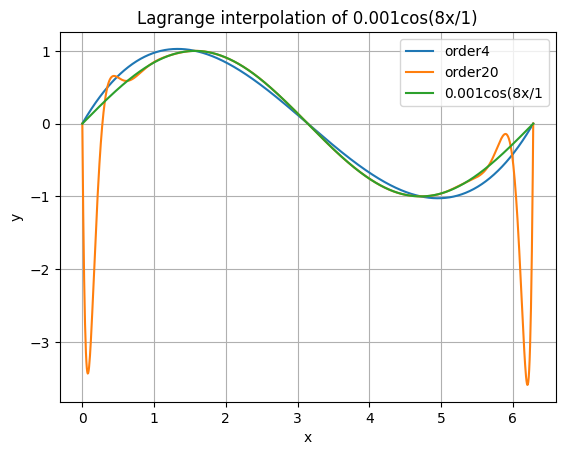

<Figure size 1200x800 with 0 Axes>

In [ ]:
# Global interpolation of perturbed f

fHat = lambda x: f(x) + 10**(-3)*np.cos((8*x/p))

I = [0, 2*np.pi*p]

points = int(1e3 + 1)
Xq = np.linspace(I[0], I[1], points)

for n in {4, 20}:
    coeffs = lagrangeInterp(fHat, I, n)
    fVals = evaluateInterpolant(coeffs, I, Xq, 1)
    plt.plot(Xq, fVals ,label =  f'order{n}')

plt.plot(Xq, f(Xq), label = f'{10**(-3)}cos(8x/{p}')
plt.legend()
plt.grid(True)
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Lagrange interpolation of {10**(-3)}cos(8x/{p})')
plt.figure(figsize=(12, 8))
plt.show()







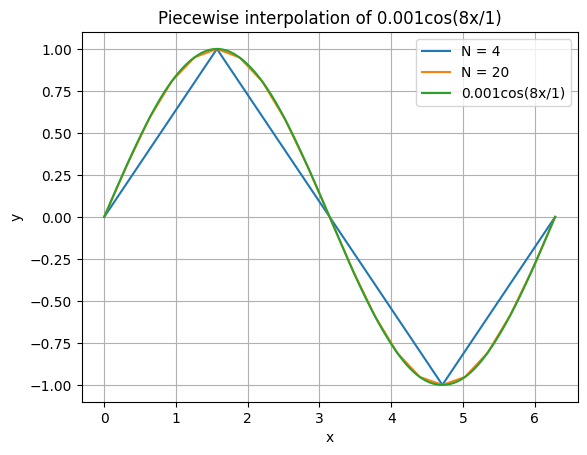

<Figure size 1200x800 with 0 Axes>

In [ ]:
# Piecewise interepolation of perturbed f

for N in {4, 20}:
    coeffsPieceHat, intervals = piecewiseInterp(fHat, I, 1, N)
    fValsPieceHat = evaluateInterpolant(coeffsPieceHat, intervals, Xq, N)
    plt.plot(Xq, fValsPieceHat ,label =  f'N = {N}')

plt.plot(Xq, fHat(Xq), label = f'{10**(-3)}cos(8x/{p})')
plt.legend()
plt.grid(True)
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Piecewise interpolation of {10**(-3)}cos(8x/{p})')
plt.figure(figsize=(12, 8))
plt.show()

# N = 4 subintervals AND N = 20 subintervals

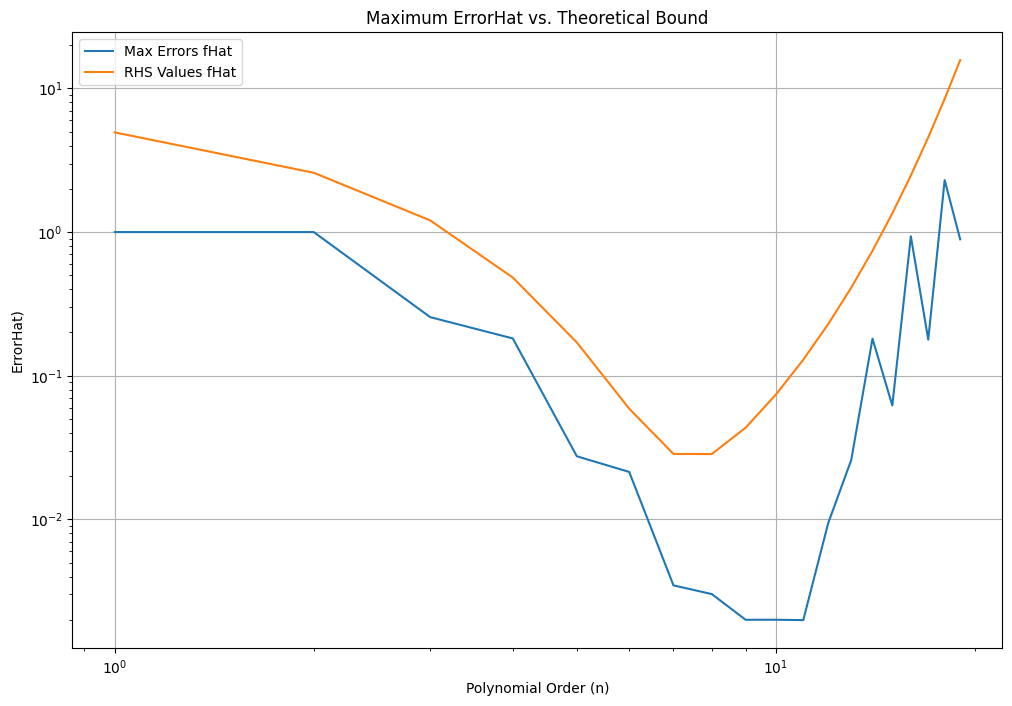

In [ ]:
# B.3 part a.)

maxErrorsHat = []
ordersnHat = []
RHSValuesHat = []
L = I[1] - I[0]
gamma = 0.5772
e = 2.7183
maxEpsilon = 10 ** (-3)

for n in range(1, 20):
    newError = MaxError(fHat, I, n)
    coeffs = lagrangeInterp(fHat, I, n)
    maxErrorsHat.append(np.max(newError))
    ordersnHat.append(n)

    Lambda = ((2**(n +1))/(e * n * np.log10(n) + gamma))
    Lebesgue = Lambda * maxEpsilon


    # Calculate RHSValues inside the loop for each n
    if n > 0:
      h = L / n
      # Max{(n+1)-th derivative of sin(x/p)} = (1/p)**(n+1).
      # Max{(n+1)-th derivative of 10**(-3)*cos(8x/p)} =  10**(-3)*(8/p)**(n+1).
      max_f_nplus1_deriv = (1/p)**(n + 1)
      rhs_valHat = (h**(n+1)) * (max_f_nplus1_deriv /(4 * (n + 1))) + Lebesgue
      RHSValuesHat.append(rhs_valHat)
    else:
      RHSValuesHat.append(0)


plt.figure(figsize=(12, 8))

plt.loglog(ordersnHat, maxErrorsHat, label='Max Errors fHat')
plt.loglog(ordersnHat, RHSValuesHat, label='RHS Values fHat')
plt.legend()
plt.grid(True)
plt.xlabel('Polynomial Order (n)')
plt.ylabel('ErrorHat)')
plt.title('Maximum ErrorHat vs. Theoretical Bound')

plt.show()

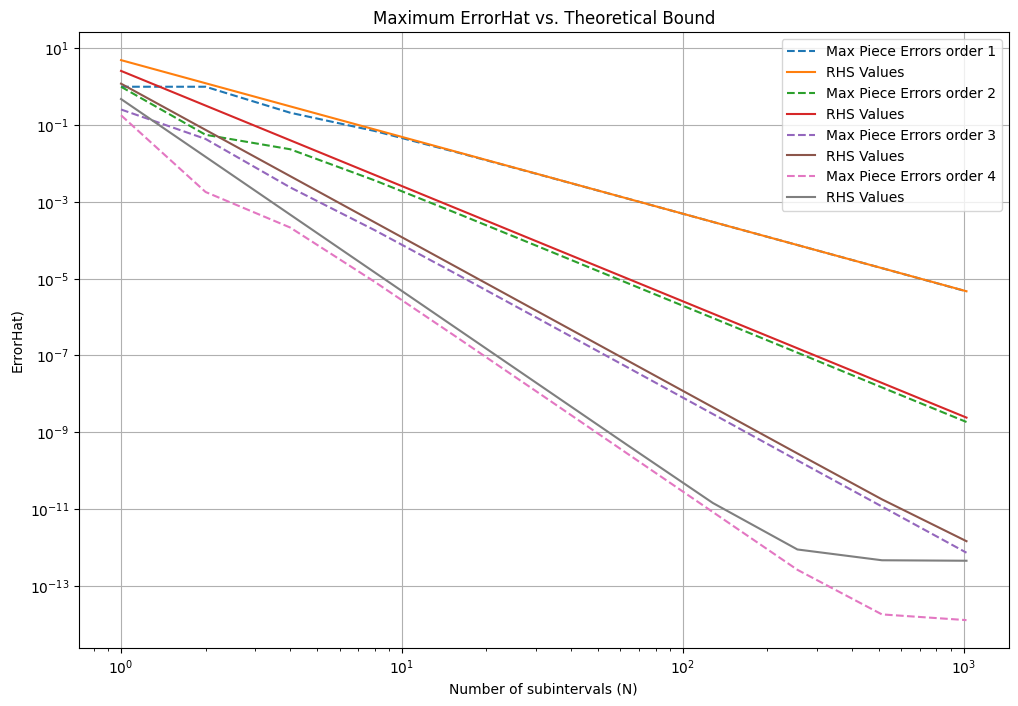

In [ ]:
## Discussion question b.)
maxEpsilon2 = 10 ** (-13)

plt.figure(figsize=(12, 8))

for n in range(1, 5):
    maxPieceErrorsHat = []
    ordersnPieceHat = []
    RHSValuesPieceHat = []
    L = I[1] - I[0]

    for j in range(0, 11):
        N = 2 ** j
        H = L / (N * n)
        newError = ErrorPiece(f, I, n, N)
        coeffs = piecewiseInterp(f, I, n, N)
        maxPieceErrorsHat.append(np.max(newError))
        ordersnPieceHat.append(N)
        # if n >= 2:
        #     Lambda = (2**(n + 1)/(e * n * np.log(n) + gamma))
        # else:
        #     Lambda = (2**(n + 1)/(gamma))

        Lambda = (( 2 ** (n + 1))/(e * n * np.log10(n) + gamma))

        Lebesgue = Lambda * maxEpsilon2


        # Calculate RHSValues inside the loop for each n
        if n > 0:
           max_f_nplus1_deriv = (1/p)**(n + 1)
           rhs_valHat = ( H ** (n+1)) * (max_f_nplus1_deriv / (4*(n + 1))) + Lebesgue
           RHSValuesPieceHat.append(rhs_valHat)
        else:
           RHSValuesHat.append(0)


    plt.loglog(ordersnPieceHat, maxPieceErrorsHat, '--', label= f'Max Piece Errors order {n}')
    plt.loglog(ordersnPieceHat, RHSValuesPieceHat, label='RHS Values')

plt.grid(True)
plt.legend()
plt.xlabel('Number of subintervals (N)')
plt.ylabel('ErrorHat)')
plt.title('Maximum ErrorHat vs. Theoretical Bound')
plt
plt.show()

## **C. Newton-Cotes quadrature**

In [ ]:
## Composite integration
#
# INPUT
# f                 f scalar-valued function
# interval          interpolation interval [a, b]
# n                 interpolation order
# N                 number of subintervals
#
# OUTPUT
# num_integral      approximate integral


def compositeIntegr(f, interval, n, N):

    a, b = interval

    coeffsInteg, intervalsInteg = piecewiseInterp(f, interval, n, N)

    num_integral = 0.0

    for i in range(N):
        coeffs = coeffsInteg[i]       # coefficients c_i
        aNew, bNew = intervalsInteg[i]  # interval endpoints


        midpoint = (aNew + bNew) / 2

        integralNew = 0.0

        j = 0

        while j < len(coeffs):
            c = coeffs[j]
            power = n + 1 - j
            integralNew += c / power * ((bNew - midpoint)**power - (aNew - midpoint)**power)
            j += 1

        num_integral += integralNew



    return num_integral



In [ ]:
## Discussion question c.)

import numpy as np

IntervalC = [0, 1]


f1 = lambda x: x
f2 = lambda x: x**2
f3 = lambda x: x**3
f4 = lambda x: x**4

I1Exact = 1/2
I2Exact = 1/3
I3Exact = 1/4
I4Exact = 1/5

print("Trapezoidal rule (n = 1)")

I1 = compositeIntegr(f1, IntervalC, 1, 1)
I2 = compositeIntegr(f2, IntervalC, 1, 1)
I3 = compositeIntegr(f3, IntervalC, 1, 1)
I4 = compositeIntegr(f4, IntervalC, 1, 1)

print("x error   =", abs(I1 - I1Exact))
print("x^2 error =", abs(I2 - I2Exact))
print("x^3 error =", abs(I3 - I3Exact))
print("x^4 error =", abs(I4 - I4Exact))

print("Simpsons rule (n = 2)")

I1simpson = compositeIntegr(f1, IntervalC, 2, 1)
I2simpson = compositeIntegr(f2, IntervalC, 2, 1)
I3simpson = compositeIntegr(f3, IntervalC, 2, 1)
I4simpson = compositeIntegr(f4, IntervalC, 2, 1)

print("x error   =", abs(I1simpson - I1Exact))
print("x^2 error =", abs(I2simpson - I2Exact))
print("x^3 error =", abs(I3simpson - I3Exact))
print("x^4 error =", abs(I4simpson - I4Exact))


Trapezoidal rule (n = 1)
x error   = 1.1102230246251565e-16
x^2 error = 0.1666666666666668
x^3 error = 0.2500000000000001
x^4 error = 0.3000000000000001
Simpsons rule (n = 2)
x error   = 1.1102230246251565e-16
x^2 error = 5.551115123125783e-17
x^3 error = 5.551115123125783e-17
x^4 error = 0.008333333333333304


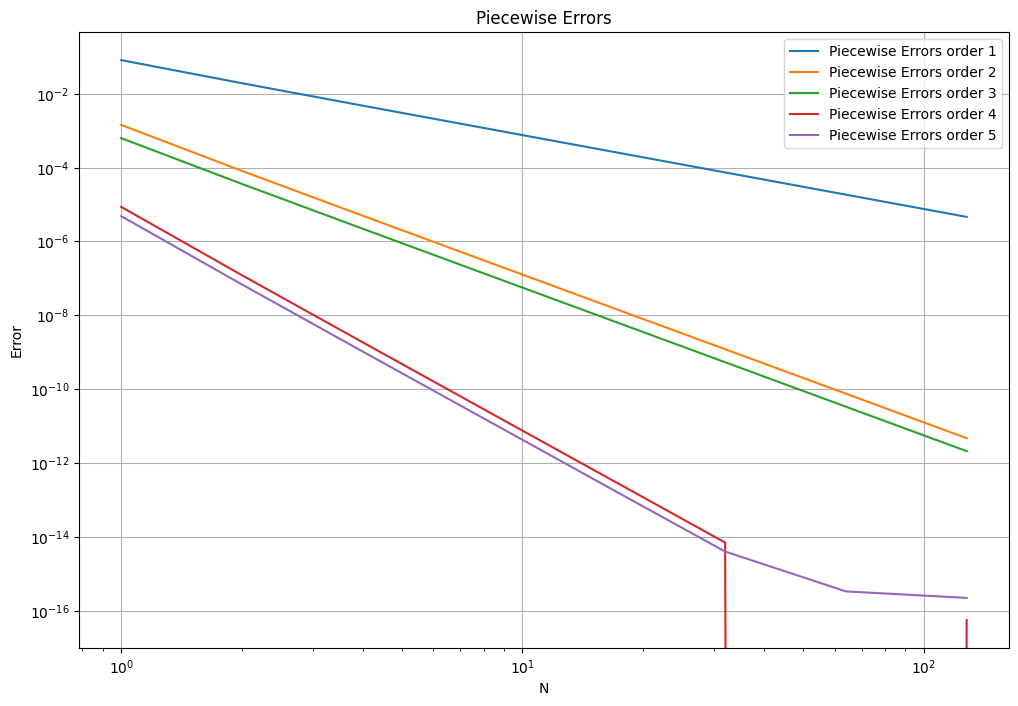

In [ ]:
## Discussion question c.2)

plt.figure(figsize=(12, 8))

q = lambda x: (np.sin(x))**2
Interval = [0, 1]

qHat = compositeIntegr(q, Interval, n, N)

Interval2 = [0, 1]
L = Interval2[1] - Interval2[0]
newInterval = []


finalErrors = []
for n in range(1, 6):
    maxPieceErrors = []
    intervalsN = []

    for i in range(0, 8):
        N = 2 ** i
        H = L / N
        intervalsN.append(N)
        x_nodes = np.linspace(Interval2[0], Interval2[1], N+1)
        error = abs(((1 - np.cos(1)*np.sin(1))/2) - compositeIntegr(q, Interval2, n, N))
        maxPieceErrors.append(error)

    finalErrors.append(maxPieceErrors)
    newInterval.append(intervalsN)

    plt.loglog(newInterval[n - 1] ,finalErrors[n - 1], label = f'Piecewise Errors order {n }')
plt.legend()
plt.xlabel('N')
plt.ylabel('Error')
plt.title('Piecewise Errors')
plt.grid(True)
plt.show()


## **D. Gauss-Legendre quadrature**

1.9899924966004454
1.9387093455447393
1.9899924654762877
[[np.float64(1.9899924966004454), np.float64(1.0024924632117178), np.float64(0.08540017271176858), np.float64(0.015311518092150367), np.float64(0.0033205276750492008), np.float64(0.0007767440959334238), np.float64(0.0001880313792261834), np.float64(4.626817109598669e-05)], [np.float64(1.9899924966004454), np.float64(0.05128315105570613), np.float64(0.0004756687582496699), np.float64(1.563139965310434e-05), np.float64(7.379711699506686e-07), np.float64(4.0414301016866716e-08), np.float64(2.3687636296898518e-09), np.float64(1.434334873096077e-10)], [np.float64(1.9899924966004454), np.float64(0.0010099371860772255), np.float64(1.0216233066184799e-06), np.float64(6.154880161091114e-09), np.float64(6.326006385393157e-11), np.float64(8.111289417911394e-13), np.float64(1.0880185641326534e-14), np.float64(0.0)], [np.float64(1.9899924966004454), np.float64(1.0444065314363371e-05), np.float64(1.1600091998076323e-09), np.float64(1.281419415

/tmp/ipython-input-3649544738.py:91: RuntimeWarning: divide by zero encountered in log
  logError = np.log(ErrorsLegQuad[i-1])


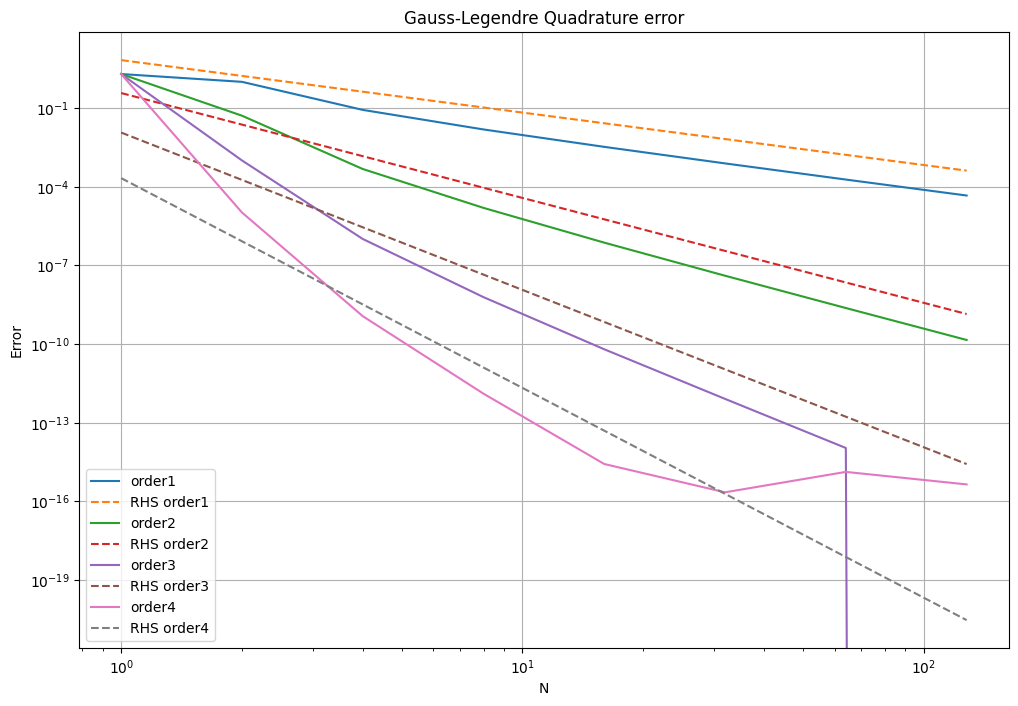

In [ ]:
## Discussion question d.)

f = lambda x: np.sin(x)
I = [0 , 3]

fIntegrated = lambda x: - np.cos(x)
fIntegral = fIntegrated(I[1]) - fIntegrated(I[0])
print(fIntegral)


def gaussLegQuad(m):
  if m == 1:
    return [0] , [2]
  if m == 2:
    return [3 ** (-1/2), - 3 ** (-1/2)], [1,1]
  if m == 3:
    return[0, (3/5) ** (1/2), - (3/5) ** (1/2)], [8/9, 5/9, 5/9]
  if m == 4:
    return [np.sqrt((1/7)*(3 - (2 * np.sqrt(6/5)))), -np.sqrt((1/7)*(3 - (2 * np.sqrt(6/5)))), np.sqrt((1/7)*(3 + (2 * np.sqrt(6/5)))), -np.sqrt((1/7)*(3 + (2 * np.sqrt(6/5))))], [(18 + np.sqrt(30)) / 36, (18 + np.sqrt(30)) / 36,(18 - np.sqrt(30)) / 36,(18 - np.sqrt(30)) / 36]

def compositeIntegralGaussLeg(f, interval, m, N):
  a, b = interval
  nodes, weights = gaussLegQuad(m)
  num_integral = 0
  subIntervals = np.linspace(a, b, N)

  for j in range(1, N):
    aNew = subIntervals[j - 1]
    bNew = subIntervals[j]
    c = (bNew - aNew) / 2
    for i in range(len(nodes)):
       num_integral += c * weights[i] * f(c * nodes[i] + (aNew + bNew) / 2)

  return num_integral

print(compositeIntegralGaussLeg(f, I, 2, 2))
print(compositeIntegralGaussLeg(f, I, 4, 3))



ErrorsLegQuad = []


for m in range(1, 5):
    ErrorOrderM = []
    Nlist = []
    for l in range(0, 8):
      N = 2 ** l
      error = abs(fIntegral - compositeIntegralGaussLeg(f, I, m, N))
      ErrorOrderM.append(error)
      Nlist.append(N)
    ErrorsLegQuad.append(ErrorOrderM)

print(ErrorsLegQuad)


plt.figure(figsize=(12, 8))


RHS = []
for m in range(1,5):
    a,b = I
    bounds = []
    for N in Nlist:
        bound = (((b-a)**(2*m+1)) / ( 4*m * (2*m - 1)** (2 * m) * N ** (2*m) ))
        bounds.append(bound)
    RHS.append(bounds)

for i in range(1,5):
    plt.loglog(Nlist, ErrorsLegQuad[i-1], label = f'order{i}')
    plt.loglog(Nlist, RHS[i-1], '--', label = f'RHS order{i}')


plt.xlabel("N")
plt.ylabel("Error")
plt.title("Gauss-Legendre Quadrature error")
plt.legend()
plt.grid(True)

plt.plot()

for i in range(1,5):
    logRHS = np.log(RHS[i-1])
    logN = np.log(Nlist)
    slope = np.gradient(logRHS, logN)
    # print(f"Slope of RHS for order {i}: {slope}")
    slope, intercept = np.polyfit(logN, logRHS, 1)
    print(f"Global slope of RHS for order {i}: {slope}")

for i in range(1,5):
    logError = np.log(ErrorsLegQuad[i-1])
    logN = np.log(Nlist)
    slope = np.gradient(logError, logN)
    # print(f"Slope of error for order {i}: {slope}")
    slope, intercept = np.polyfit(logN, logError, 1)
    print(f"Global slope of errors for order {i}: {slope}")
